# Hourly electricity-price analysis and forecasting

The exploratory analysis below is retained from the original notebook. The
**revised machine-learning section** rebuilds features directly from `df`;
full-series exploratory statistics are not passed into model training.

The forecasting task is **one hour ahead, updated every hour**. This is a
historical backtest, not a live forecast beyond the CSV's last timestamp.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from xgboost import XGBRegressor
from scipy import stats
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, ccf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


1. Set time

In [2]:
from pathlib import Path
data_candidates = [Path('energy_dataset.csv'), Path('/Users/jiongwu/Documents/Python_Leetcode/Squarepoint/data-anlysis/energy_dataset.csv')]
DATA_PATH = next((p for p in data_candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Set DATA_PATH to your energy_dataset.csv file.')
df = pd.read_csv(DATA_PATH)
df['time'] = pd.to_datetime(df['time'], utc=True)
df = df.set_index('time').sort_index().tz_convert('Europe/Madrid')
expected_time = pd.date_range(df.index.min(), df.index.max(), freq='h')
assert df.index.equals(expected_time), 'Check the complete hourly timeline first'
assert df.index.is_unique
df.head()


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,863.0,1051.0,1899.0,0.0,7096.0,43.0,73.0,49.0,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,920.0,1009.0,1658.0,0.0,7096.0,43.0,71.0,50.0,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,1164.0,973.0,1371.0,0.0,7099.0,43.0,73.0,50.0,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,NaN,1503.0,949.0,779.0,0.0,7098.0,43.0,75.0,50.0,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,NaN,1826.0,953.0,720.0,0.0,7097.0,43.0,74.0,42.0,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


2. Check NA and duplicated

In [3]:
print(len(df))
df_audit = pd.DataFrame({
    'recorded values': df.count(),
    'recorded zero': df.eq(0).sum(),
    'NaN values': df.isna().sum(),
    'duplicated': df.index.duplicated().sum()
})
df_audit

35064


,recorded values,recorded zero,NaN values,duplicated
generation biomass,35045,4,19,0
generation fossil brown coal/lignite,35046,10517,18,0
generation fossil coal-derived gas,35046,35046,18,0
generation fossil gas,35046,1,18,0
generation fossil hard coal,35046,3,18,0
generation fossil oil,35045,3,19,0
generation fossil oil shale,35046,35046,18,0
generation fossil peat,35046,35046,18,0
generation geothermal,35046,35046,18,0
generation hydro pumped storage aggregated,0,0,35064,0


In [4]:
supply = df.drop(columns=['generation fossil coal-derived gas', 'generation fossil oil shale', 'generation fossil peat',
                          'generation geothermal', 'generation hydro pumped storage aggregated', 'generation marine',
                          'generation wind offshore', 'forecast solar day ahead', 'forecast wind offshore eday ahead', 
                          'forecast wind onshore day ahead', 'total load forecast']).copy()
supply.columns = supply.columns.str.removeprefix('generation ')
supply[supply.isnull().any(axis=1)].head(5)


,biomass,fossil brown coal/lignite,fossil gas,fossil hard coal,fossil oil,hydro pumped storage consumption,hydro run-of-river and poundage,hydro water reservoir,nuclear,other,other renewable,solar,waste,wind onshore,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,
2015-01-05 03:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21182.0,35.2,59.68
2015-01-05 12:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.5,79.14
2015-01-05 13:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.8,73.95
2015-01-05 14:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.5,71.93
2015-01-05 15:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,71.50


Find outliers

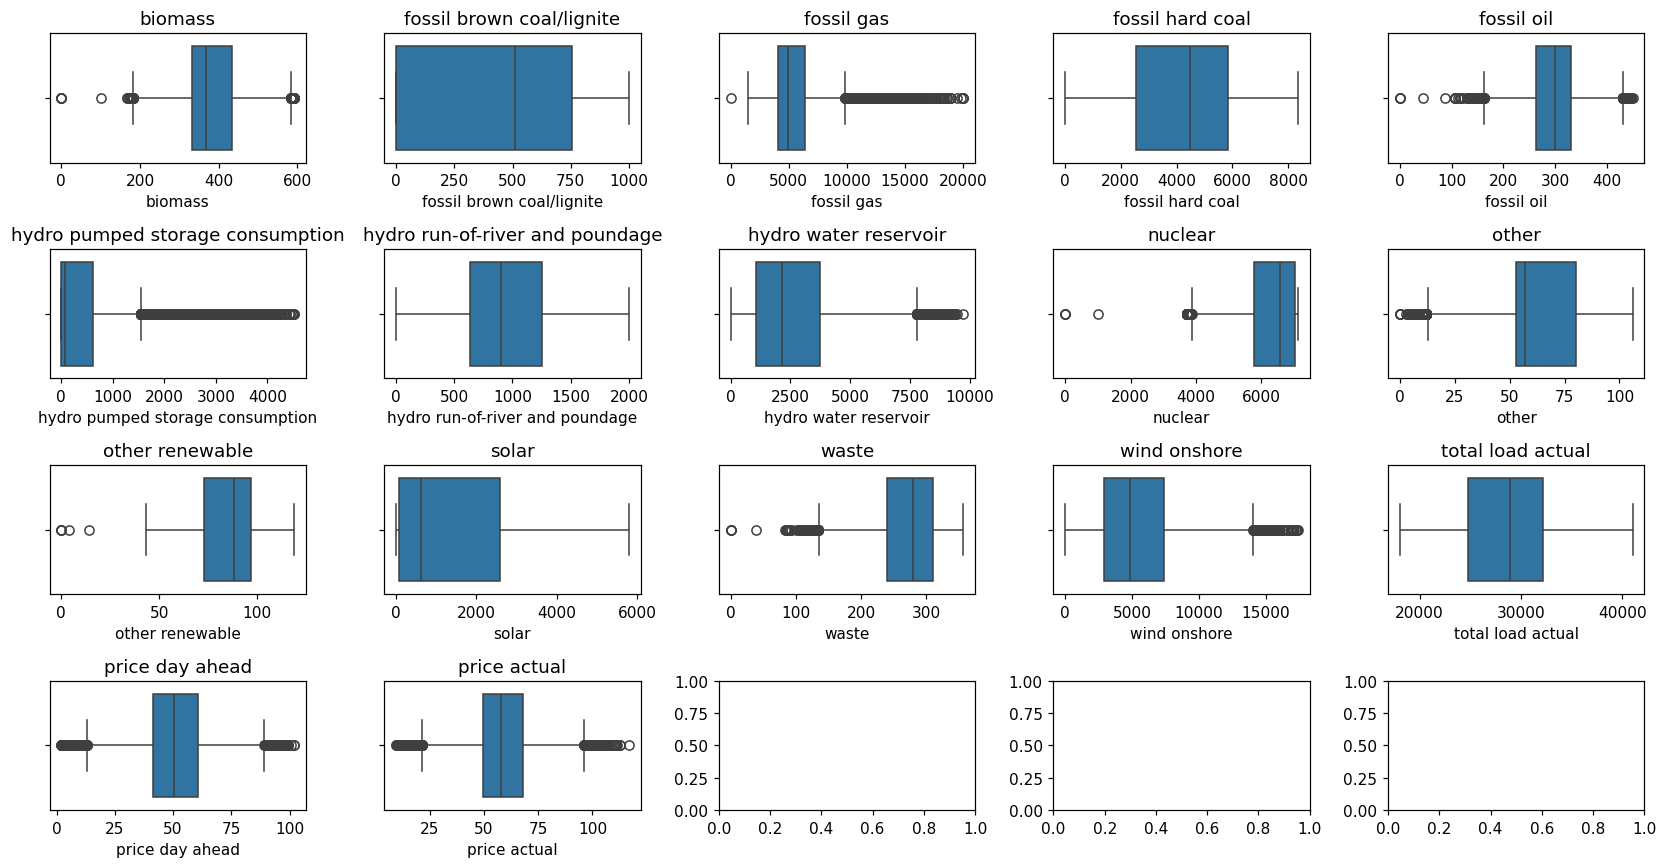

In [5]:
fig, axes = plt.subplots(4, 5, figsize=(15, 8))
for column, ax in zip(supply.columns, axes.flat):
    sns.boxplot(ax=ax, x=supply[column])
    ax.set_title(column)
plt.tight_layout()
plt.show()

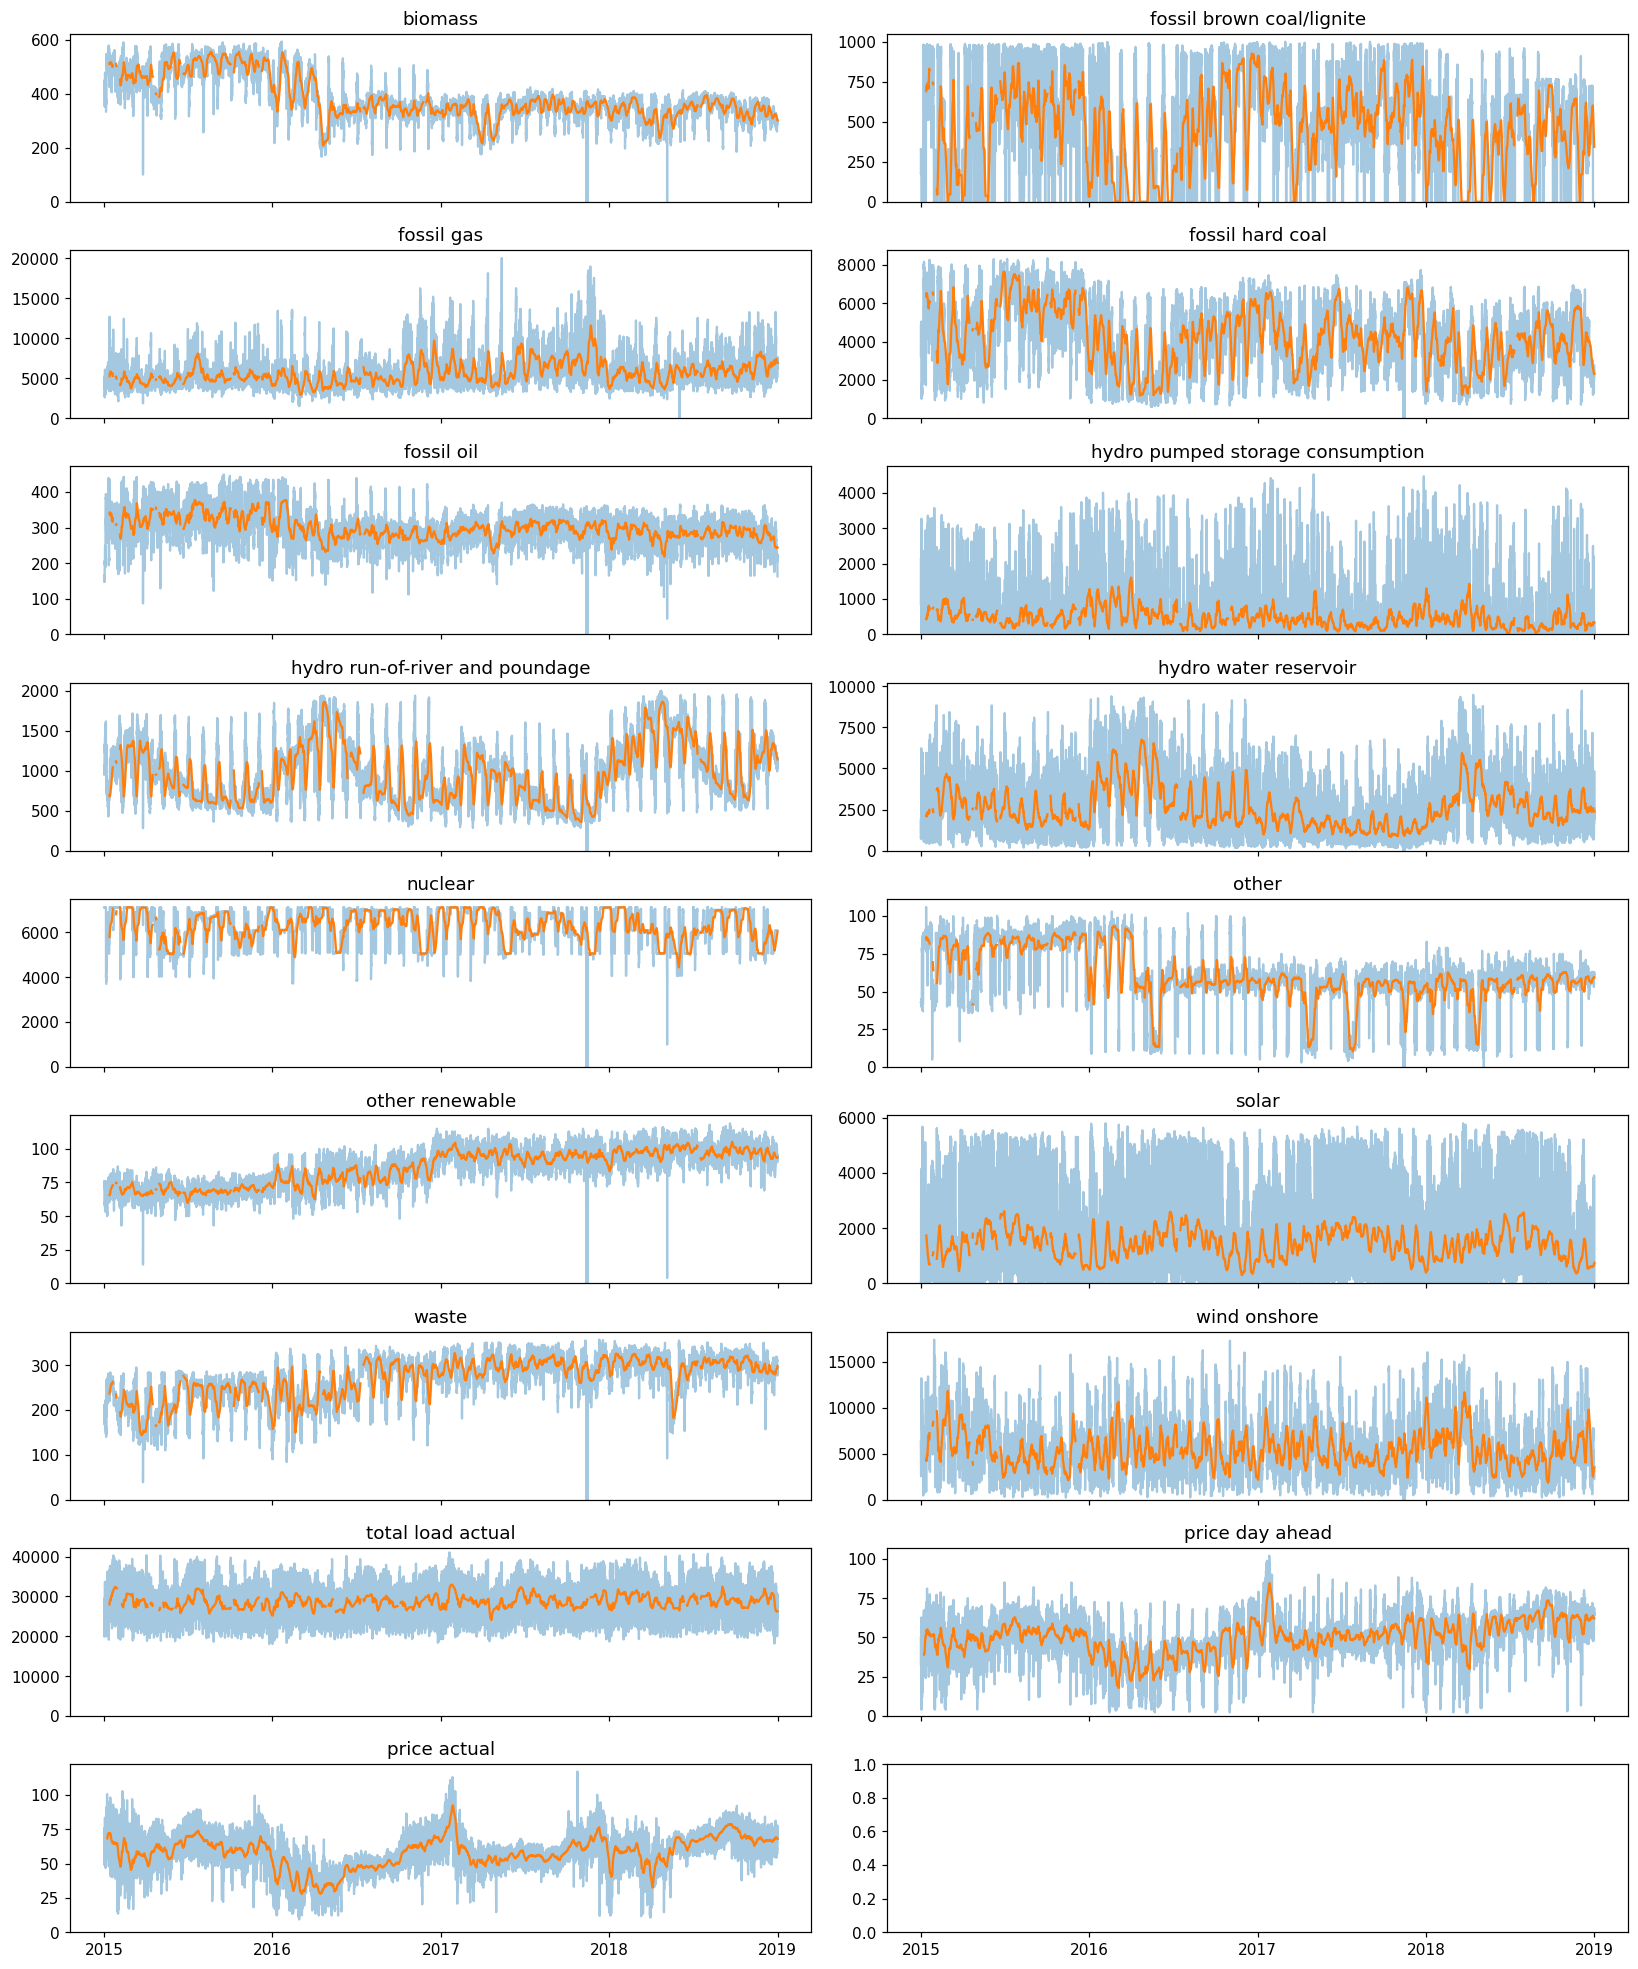

In [6]:
fig, axes = plt.subplots(9, 2, figsize=(15, 18), sharex=True)
for column, ax in zip(supply.columns, axes.flat):
    ax.plot(supply.index, supply[column], alpha=0.4, color='tab:blue')
    ax.plot(supply.index, supply[column].rolling(7*24).mean(), color='tab:orange')
    ax.set_ylim(bottom=0)
    ax.set_title(column)
axes[-1, 0].xaxis.set_major_locator(mdates.YearLocator())
plt.tight_layout()
plt.show()

Analyze solar

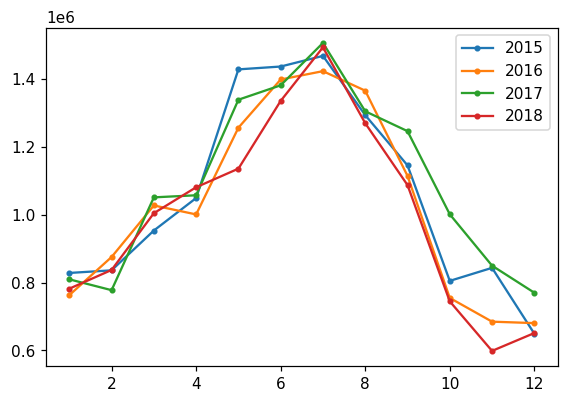

In [7]:
solar_monthly = supply['solar'].resample('MS').sum()
profile = solar_monthly.groupby([solar_monthly.index.year, solar_monthly.index.month]).sum().unstack(level=0)

fig, ax = plt.subplots(figsize=(6, 4))
for year in profile.columns:
    ax.plot(profile.index, profile[year], '.-', label=year)

ax.legend()
plt.show()

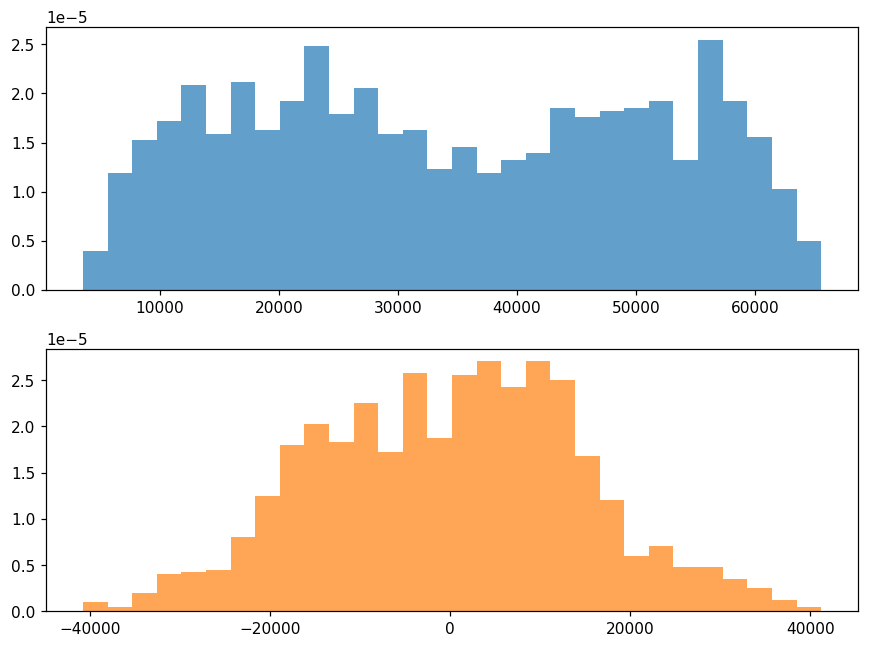

In [8]:
solar_daily = supply['solar'].resample('D').sum()
month_mean= solar_daily.groupby(solar_daily.index.month).transform('mean')
solar_daily_adjusted = solar_daily - month_mean

fig, axes = plt.subplots(2, 1, figsize=(8, 6))
axes[0].hist(solar_daily.dropna(), bins=30, color='tab:blue', density=True, alpha=0.7)
axes[1].hist(solar_daily_adjusted.dropna(), bins=30, color='tab:orange', density=True, alpha=0.7)
plt.tight_layout()
plt.show()

,n,skewness,kurtosis
origin,1461.0,0.039571,-1.267427
monthly mean adjusted,1461.0,0.001856,-0.340081
YoeJohnson transformed,1461.0,0.067606,-0.325721


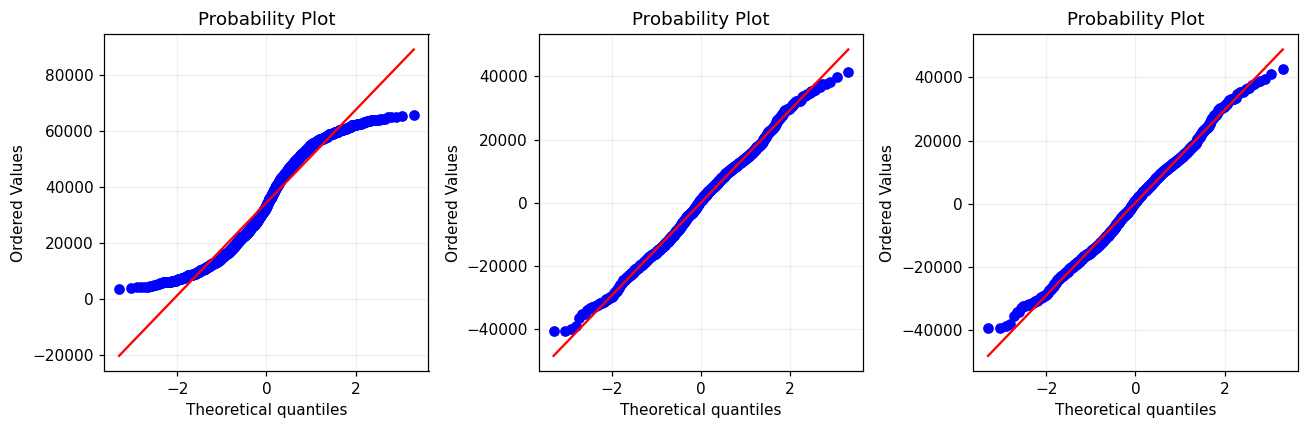

In [9]:
def distribution_summary(series):
    series.dropna()
    return pd.Series({'n': len(series), 'skewness': series.skew(), 'kurtosis': series.kurtosis()})

transformed_values, fit_lambda = stats.yeojohnson(solar_daily_adjusted.dropna().to_numpy())
transformed = pd.Series(transformed_values, index=solar_daily_adjusted.index, name='YeoJohnson')

description = pd.DataFrame({
    'origin': distribution_summary(solar_daily),
    'monthly mean adjusted': distribution_summary(solar_daily_adjusted),
    'YoeJohnson transformed': distribution_summary(transformed)
}).T
display(description)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, series, label in zip(axes, [solar_daily, solar_daily_adjusted, transformed], ['Original', 'Monthly adjusted', 'Yeo-Johnson adjusted']):
    stats.probplot(series.dropna(), dist='norm', plot=ax)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

Analyze water

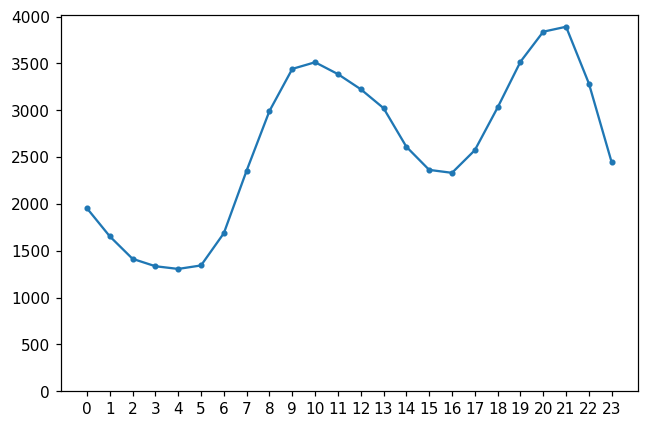

In [10]:
water_hourly_mean = supply['hydro water reservoir'].groupby(supply.index.hour).mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(water_hourly_mean.index, water_hourly_mean, '.-')
ax.set_ylim(bottom=0)
ax.set_xticks(range(24))
fig.tight_layout()
plt.show()

price actual analysis

n           35064.000000
skewness       -0.323749
kurtosis        0.469561
dtype: float64
n           35064.000000
skewness        0.008589
kurtosis        0.277816
dtype: float64


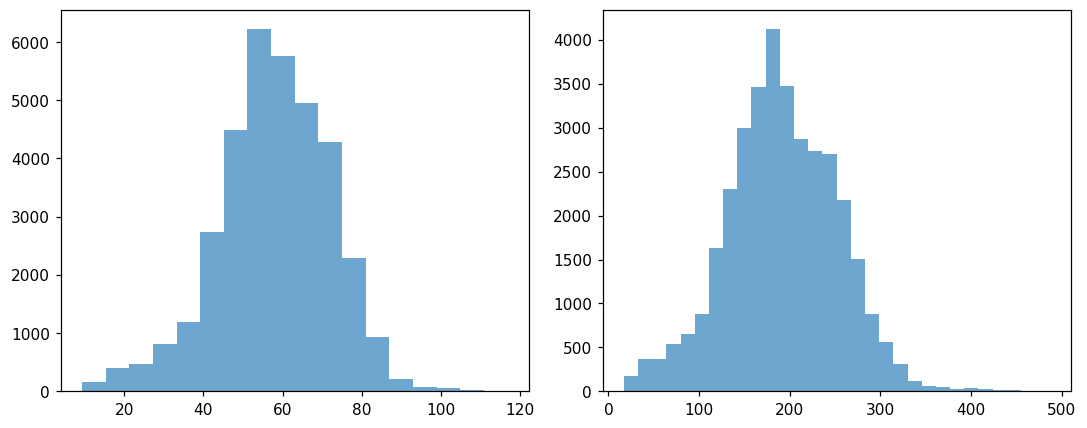

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
values = supply['price actual'].dropna()
axes[0].hist(values, bins=18, alpha=0.65,)
print(distribution_summary(supply['price actual']))

transformed_values, fit_lambda = stats.yeojohnson(values.dropna().to_numpy())
transformed = pd.Series(transformed_values, index=values.index, name='YeoJohnson')
axes[1].hist(transformed, bins=30, alpha=0.65)
print(distribution_summary(transformed))
plt.tight_layout()
plt.show()

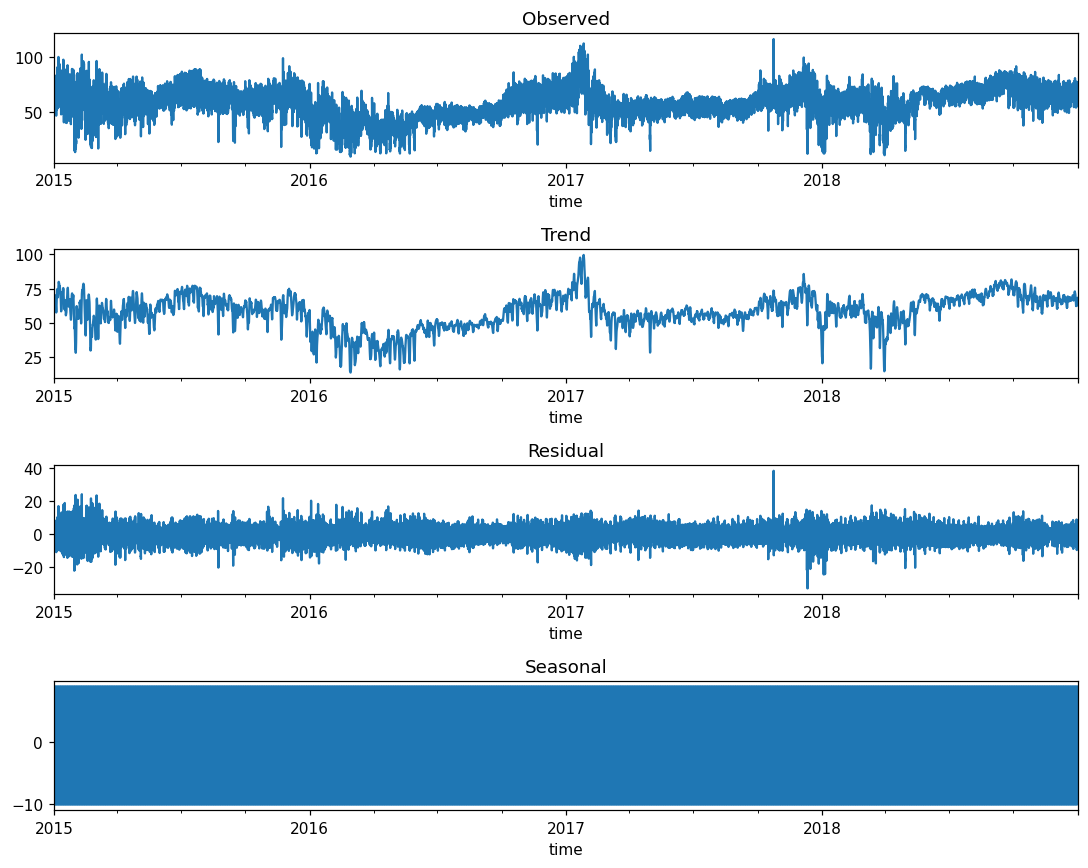

ADF Statistic: -9.147016
p-value: 0.000000
#Lags used: 50
Critical Value (1%): -3.430537
Critical Value (5%): -2.861623
Critical Value (10%): -2.566814


In [12]:
res = sm.tsa.seasonal_decompose(supply['price actual'], model='additive')

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(10, 8))
res.observed.plot(ax=ax1, title='Observed')
res.trend.plot(ax=ax2, title='Trend')
res.resid.plot(ax=ax3, title='Residual')
res.seasonal.plot(ax=ax4, title='Seasonal')
plt.tight_layout()
plt.show()

y = supply['price actual']
adf_test = adfuller(y, regression='c')
print('ADF Statistic: {:.6f}\np-value: {:.6f}\n#Lags used: {}'
      .format(adf_test[0], adf_test[1], adf_test[2]))
for key, value in adf_test[4].items():
    print('Critical Value ({}): {:.6f}'.format(key, value))

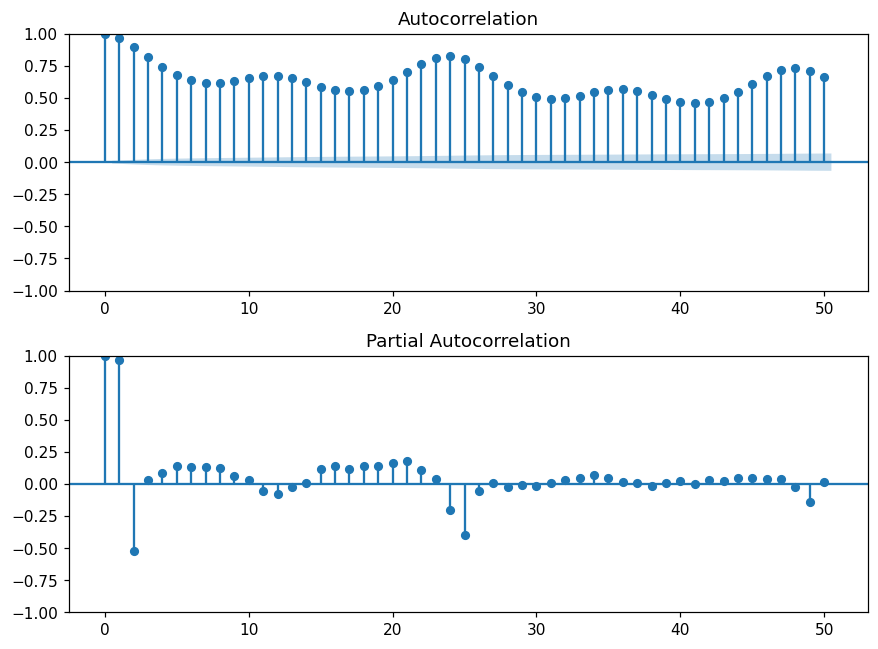

In [13]:
fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(8, 6))
plot_acf(supply['price actual'], lags=50, ax=ax1)
plot_pacf(supply['price actual'], lags=50, ax=ax2)
plt.tight_layout()
plt.show()

In [14]:
correlations = supply.corr(method='pearson', numeric_only=True)
target_corr = correlations['price actual'].drop('price actual')
top_corr = target_corr.loc[target_corr.abs().nlargest(10).index]
display(top_corr)

price day ahead                     0.732155
fossil hard coal                    0.465641
fossil gas                          0.461706
total load actual                   0.436127
hydro pumped storage consumption   -0.426417
fossil brown coal/lignite           0.364088
fossil oil                          0.284679
other renewable                     0.256181
wind onshore                       -0.220830
waste                               0.169605
Name: price actual, dtype: float64

In [15]:
highly_correlated = abs(correlations[correlations > 0.5])
print(highly_correlated[highly_correlated < 1].stack().to_string())

biomass                          other                              0.658488
fossil brown coal/lignite        fossil hard coal                   0.768710
                                 price day ahead                    0.567905
fossil gas                       fossil hard coal                   0.541635
                                 total load actual                  0.548913
                                 price day ahead                    0.640895
fossil hard coal                 fossil brown coal/lignite          0.768710
                                 fossil gas                         0.541635
                                 price day ahead                    0.671596
hydro run-of-river and poundage  hydro water reservoir              0.652769
hydro water reservoir            hydro run-of-river and poundage    0.652769
other                            biomass                            0.658488
other renewable                  waste                              0.613945

## Revised ML pipeline: Ridge and Ridge + XGBoost

Each row represents the **target hour t**. Predict `price actual[t]` using:

- Actual price, load and generation only through `t - ACTUAL_DELAY_HOURS`.
- Target-hour day-ahead prices and load/solar/wind forecasts assumed published
  by the prediction origin, plus known calendar information.
- Past-only rolling statistics, built on the complete hourly grid.

The CSV has no publication timestamps. The default assumes the latest actuals
are available with a one-hour lag. Increase the delay and rerun selection if
your feed arrives later. Historical actuals from earlier test hours may enter
later predictions: this matches hourly updating, not a single six-month forecast.

Feature sets, Ridge regularization, training-window length and the residual
correction are selected using **2017 Q3–2018 Q2** only. The final test starts
**1 July 2018**. Late-2018 outcomes were inspected in earlier analysis, so this
is a reserved historical comparison within this workflow, not pristine unseen data.


In [16]:
import os
import json
import hashlib
import platform
import joblib
import sklearn
import xgboost
from itertools import product
from threadpoolctl import threadpool_limits
from IPython.display import display

OUTPUT_DIR = Path(os.environ.get('ENERGY_FORECAST_OUTPUT_DIR',
                                str(Path.cwd() / 'ridge_forecast_outputs')))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# False reuses the validation search performed for this exact CSV.
# Change to True after modifying features, availability assumptions or data.
RUN_MODEL_SEARCH = False


In [17]:
"""Causal feature construction and chronological model fitting helpers."""
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TIMEZONE = 'Europe/Madrid'
ACTUAL_DELAY_HOURS = 1
WARMUP_HOURS = 7 * 24 + ACTUAL_DELAY_HOURS
TEST_START = pd.Timestamp('2018-07-01', tz=TIMEZONE)
FOLD_DATES = [('2017-07-01', '2017-10-01'),
              ('2017-10-01', '2018-01-01'),
              ('2018-01-01', '2018-04-01'),
              ('2018-04-01', '2018-07-01')]

def load_data(path):
    frame = pd.read_csv(path)
    frame['time'] = pd.to_datetime(frame['time'], utc=True)
    frame = frame.set_index('time').sort_index().tz_convert(TIMEZONE)
    assert frame.index.is_unique
    assert frame.index.equals(pd.date_range(frame.index.min(), frame.index.max(), freq='h'))
    return frame

def make_features(frame, actual_delay=ACTUAL_DELAY_HOURS):
    """Row t predicts y[t]. All actual-series inputs end at t-actual_delay.

    Target-hour day-ahead prices and physical forecasts are assumed published.
    No backfill, centered windows, interpolation, or fitted transforms here.
    """
    if not isinstance(actual_delay, int) or actual_delay < 1:
        raise ValueError('actual_delay must be an integer of at least one hour')
    ix = frame.index
    price = frame['price actual']
    da = frame['price day ahead']
    spread = price-da
    values, groups, availability = {}, {}, {}

    def add(name, value, group, timing):
        values[name] = value
        groups.setdefault(group, []).append(name)
        availability[name] = timing

    for name, series, lags in [
        ('price',price,[1,2,3,6,12,23,24,25,48,72,168,169]),
        ('spread',spread,[1,2,3,6,24,48,168])]:
        for lag in lags:
            offset = lag + actual_delay-1
            add(f'{name}_lag{offset}',series.shift(offset),'price',f'actual <= t-{actual_delay}')
        past = series.shift(actual_delay)
        for window in [3,6,24,168]:
            rolling = past.rolling(window,min_periods=window)
            add(f'{name}_mean{window}',rolling.mean(),'price',f'actual <= t-{actual_delay}')
            add(f'{name}_std{window}',rolling.std(),'price',f'actual <= t-{actual_delay}')
        add(f'{name}_change1',past-series.shift(actual_delay+1),'price',f'actual <= t-{actual_delay}')
        add(f'{name}_change24',past-series.shift(actual_delay+24),'price',f'actual <= t-{actual_delay}')

    add('day_ahead',da,'price','target-hour published forecast')
    add('day_ahead_change1',da-da.shift(1),'price','published forecasts')
    add('day_ahead_change24',da-da.shift(24),'price','published forecasts')

    # Fixed calendar categories do not learn anything from future outcomes.
    for hour in range(1,24):
        add(f'hour_{hour:02d}',(ix.hour==hour).astype(float),'calendar','known calendar')
    for day in range(1,7):
        add(f'weekday_{day}',(ix.weekday==day).astype(float),'calendar','known calendar')
    for order in [1,2]:
        angle=2*np.pi*order*(ix.dayofyear-1)/365.25
        add(f'annual_sin{order}',np.sin(angle),'calendar','known calendar')
        add(f'annual_cos{order}',np.cos(angle),'calendar','known calendar')
    add('is_weekend',(ix.weekday>=5).astype(float),'calendar','known calendar')

    forecast_names = {'load':'total load forecast',
                      'solar':'forecast solar day ahead',
                      'wind':'forecast wind onshore day ahead'}
    actual_names = {'load':'total load actual',
                    'solar':'generation solar',
                    'wind':'generation wind onshore'}
    for name,column in forecast_names.items():
        series=frame[column]
        add(f'{name}_forecast',series,'forecasts','target-hour published forecast')
        add(f'{name}_forecast_change1',series-series.shift(1),'forecasts','published forecasts')
        error=frame[actual_names[name]]-series
        for lag in [actual_delay,actual_delay+23]:
            add(f'{name}_forecast_error_lag{lag}',error.shift(lag),'forecasts',f'actual <= t-{actual_delay}')
    residual=frame['total load forecast']-frame['forecast solar day ahead']-frame['forecast wind onshore day ahead']
    add('residual_load_forecast',residual,'forecasts','target-hour published forecast')

    physical_names=['total load actual','generation fossil gas','generation fossil hard coal',
                    'generation nuclear','generation hydro water reservoir',
                    'generation wind onshore','generation solar']
    for name in physical_names:
        s=frame[name]
        label=name.replace('generation ','').replace(' ','_')
        for lag in [actual_delay,actual_delay+23,actual_delay+167]:
            add(f'{label}_lag{lag}',s.shift(lag),'physical',f'actual <= t-{actual_delay}')
        past=s.shift(actual_delay)
        add(f'{label}_mean24',past.rolling(24,min_periods=24).mean(),'physical',f'actual <= t-{actual_delay}')
        add(f'{label}_change1',past-s.shift(actual_delay+1),'physical',f'actual <= t-{actual_delay}')

    features=pd.DataFrame(values,index=ix,dtype=float)
    feature_sets = {
        'price_calendar':groups['price']+groups['calendar'],
        'with_forecasts':groups['price']+groups['calendar']+groups['forecasts'],
        'with_physical_history':sum([groups[g] for g in ['price','calendar','forecasts','physical']],[]),
    }
    baseline=da+spread.shift(actual_delay)
    baseline.name='day_ahead_plus_previous_spread'
    manifest=pd.DataFrame({'feature':list(values),'availability':[availability[k] for k in values]})
    return features,price.rename('actual'),baseline,feature_sets,manifest

def metric_dict(y,pred):
    return {'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'MAE':float(mean_absolute_error(y,pred)),
            'R2':float(r2_score(y,pred)),
            'bias':float(np.mean(np.asarray(pred)-np.asarray(y)))}

def train_mask(index, end, lookback_days=None):
    mask=index<end
    if lookback_days is not None:
        mask &= index>=end-pd.Timedelta(days=lookback_days)
    return mask

def get_folds(index):
    return [(label,pd.Timestamp(start,tz=TIMEZONE),pd.Timestamp(end,tz=TIMEZONE))
            for label,(start,end) in zip(['2017 Q3','2017 Q4','2018 Q1','2018 Q2'],FOLD_DATES)]

def build_ridge(alpha):
    return make_pipeline(SimpleImputer(strategy='median',add_indicator=True),
                         StandardScaler(),Ridge(alpha=float(alpha)))

def fit_ridge(features,y,baseline,config,train):
    offset=baseline if config['target']=='baseline_residual' else pd.Series(0.,index=y.index)
    model=build_ridge(config['alpha'])
    model.fit(features.loc[train],(y-offset).loc[train])
    return model,offset


In [18]:
X_all, Y_all, baseline_all, feature_sets, feature_manifest = make_features(
    df, actual_delay=ACTUAL_DELAY_HOURS)
warmup_hours = 168 + ACTUAL_DELAY_HOURS
keep = ((np.arange(len(df)) >= warmup_hours)
        & Y_all.notna() & baseline_all.notna())
X = X_all.loc[keep].copy()
Y = Y_all.loc[keep].copy()
baseline = baseline_all.loc[keep].copy()
# Keep physical-feature NaNs. Median imputation is fitted inside training folds.
dev = X.index < TEST_START
test = X.index >= TEST_START
X_dev, Y_dev, baseline_dev = X.loc[dev], Y.loc[dev], baseline.loc[dev]
assert X.index.equals(Y.index) and X.index.is_unique and X.columns.is_unique
assert X.index[dev].max() < X.index[test].min()

split_rows = []
for label, start, end in get_folds(X.index):
    train = X.index < start
    valid = (X.index >= start) & (X.index < end)
    split_rows.append({'window':label, 'train_rows':int(train.sum()),
                       'validation_rows':int(valid.sum()),
                       'start':str(start), 'end_exclusive':str(end)})
display(pd.DataFrame(split_rows))
print(f'Development rows: {dev.sum():,}; test rows: {test.sum():,}')
display(pd.Series({k:len(v) for k,v in feature_sets.items()}, name='feature_count'))


,window,train_rows,validation_rows,start,end_exclusive
0,2017 Q3,21718,2208,2017-07-01 00:00:00+02:00,2017-10-01 00:00:00+02:00
1,2017 Q4,23926,2209,2017-10-01 00:00:00+02:00,2018-01-01 00:00:00+01:00
2,2018 Q1,26135,2159,2018-01-01 00:00:00+01:00,2018-04-01 00:00:00+02:00
3,2018 Q2,28294,2184,2018-04-01 00:00:00+02:00,2018-07-01 00:00:00+02:00


Development rows: 30,478; test rows: 4,417


price_calendar            76
with_forecasts            89
with_physical_history    124
Name: feature_count, dtype: int64

### Meaningful timing checks

Replacing unavailable actual values must not change the target-hour feature
vector. Truncating future rows must also leave it unchanged. These checks
verify computational causality, not the provider's publication schedule.


In [19]:
actual_cols = [c for c in df if c.startswith('generation ')]
actual_cols += ['total load actual', 'price actual']
target_times = [df.index[10000], pd.Timestamp('2018-03-25 03:00', tz=TIMEZONE),
                pd.Timestamp('2018-10-28 01:00', tz='UTC').tz_convert(TIMEZONE)]
for target_time in target_times:
    altered = df.copy()
    unavailable = altered.index > target_time - pd.Timedelta(hours=ACTUAL_DELAY_HOURS)
    altered.loc[unavailable, actual_cols] = 999999.0
    altered_X, _, altered_b, _, _ = make_features(altered, ACTUAL_DELAY_HOURS)
    pd.testing.assert_series_equal(X_all.loc[target_time], altered_X.loc[target_time])
    assert baseline_all.loc[target_time] == altered_b.loc[target_time]
    prefix_X, _, _, _, _ = make_features(df.loc[:target_time], ACTUAL_DELAY_HOURS)
    pd.testing.assert_series_equal(X_all.loc[target_time], prefix_X.loc[target_time])
print('Passed: unavailable-actual and future-truncation checks, including DST transitions.')


Passed: unavailable-actual and future-truncation checks, including DST transitions.


### Select Ridge on chronological validation

Compare three feature sets, five alpha values, expanding versus 365-day
training, and two targets: price directly or a correction to
`day_ahead[t] + (actual - day_ahead)[t-1]`. The latter baseline adapts to the
latest observed premium. Imputation and standardization are trained afresh
inside every fold. Rank candidates by pooled validation RMSE.


In [20]:
ALPHAS = [1, 10, 100, 1000, 10000]

def search_ridge(features, y, baseline, feature_sets, verbose=True):
    """Return ranked configs, per-fold scores, and OOF predictions for the winner."""
    assert features.index.max() < TEST_START
    assert features.index.equals(y.index) and features.index.equals(baseline.index)
    all_rows, fold_rows, predictions = [], [], {}
    configs = list(product(feature_sets, [None, 365], ['level', 'baseline_residual'], ALPHAS))
    with threadpool_limits(limits=2):
        for config_id, (feature_set, lookback, target, alpha) in enumerate(configs):
            config = dict(feature_set=feature_set, lookback_days=lookback, target=target, alpha=alpha)
            selected = features[feature_sets[feature_set]]
            fold_predictions = []
            for label, start, end in get_folds(features.index):
                train = train_mask(features.index, start, lookback)
                valid = (features.index >= start) & (features.index < end)
                assert features.index[train].max() < features.index[valid].min()
                model, offset = fit_ridge(selected, y, baseline, config, train)
                pred = model.predict(selected.loc[valid]) + offset.loc[valid].to_numpy()
                scores = metric_dict(y.loc[valid], pred)
                fold_rows.append(dict(config_id=config_id, **config, fold=label,
                                      n_train=int(train.sum()), n_valid=int(valid.sum()), **scores))
                fold_predictions.append(pd.DataFrame({'actual':y.loc[valid], 'prediction':pred,
                                                       'fold':label}, index=y.loc[valid].index))
            pooled = pd.concat(fold_predictions).sort_index()
            scores = metric_dict(pooled.actual, pooled.prediction)
            all_rows.append(dict(config_id=config_id, **config, n_features=selected.shape[1], **scores))
            predictions[config_id] = pooled
            if verbose and (config_id + 1) % 10 == 0:
                best = min(all_rows, key=lambda x:x['RMSE'])
                print(f'Ridge candidates {config_id + 1}/{len(configs)}; best validation RMSE {best["RMSE"]:.6f}', flush=True)
    ranked = pd.DataFrame(all_rows).sort_values(['RMSE','MAE']).reset_index(drop=True)
    best_id = int(ranked.iloc[0].config_id)
    best_raw = next(r for r in all_rows if r['config_id'] == best_id)
    best_config = {key:best_raw[key] for key in ['feature_set','lookback_days','target','alpha']}
    folds = pd.DataFrame(fold_rows)
    return best_config, ranked, folds, predictions[best_id]


In [21]:
VALIDATION_DATA_SHA256 = '14cd13e020d87af0ab49db8e0f1e4d308320ec5b8d2dec23bab4d27c75c7733a'
VALIDATION_DESIGN_SHA256 = '31d8357e9a088d309735941a5390bf3143a081bff08d4733db37671ccbeb816d'
saved_ridge_search = json.loads("{\"best_config\": {\"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 100}, \"best_scores\": {\"RMSE\": 2.1067830698502745, \"MAE\": 1.3502957230081651, \"R2\": 0.9668580978553765, \"bias\": 0.02817508989144778}, \"best_folds\": [{\"config_id\": 47, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 100, \"fold\": \"2017 Q3\", \"n_train\": 21718, \"n_valid\": 2208, \"RMSE\": 1.4932428569, \"MAE\": 0.9894457307, \"R2\": 0.9251133192, \"bias\": -0.0173495115}, {\"config_id\": 47, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 100, \"fold\": \"2017 Q4\", \"n_train\": 23926, \"n_valid\": 2209, \"RMSE\": 2.4852246118, \"MAE\": 1.5506093762, \"R2\": 0.9582037515, \"bias\": 0.0462343614}, {\"config_id\": 47, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 100, \"fold\": \"2018 Q1\", \"n_train\": 26135, \"n_valid\": 2159, \"RMSE\": 2.5099200748, \"MAE\": 1.6814453625, \"R2\": 0.9666987929, \"bias\": 0.0191059644}, {\"config_id\": 47, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 100, \"fold\": \"2018 Q2\", \"n_train\": 28294, \"n_valid\": 2184, \"RMSE\": 1.7532853118, \"MAE\": 1.1851454718, \"R2\": 0.9710145876, \"bias\": 0.0648992799}], \"top_10\": [{\"config_id\": 47, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 100, \"n_features\": 124, \"RMSE\": 2.1067830699, \"MAE\": 1.350295723, \"R2\": 0.9668580979, \"bias\": 0.0281750899}, {\"config_id\": 46, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 10, \"n_features\": 124, \"RMSE\": 2.1086553183, \"MAE\": 1.3553161518, \"R2\": 0.9667991668, \"bias\": 0.0332113608}, {\"config_id\": 41, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"level\", \"alpha\": 10, \"n_features\": 124, \"RMSE\": 2.1088827619, \"MAE\": 1.3557181102, \"R2\": 0.9667920042, \"bias\": 0.0329280617}, {\"config_id\": 45, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 1, \"n_features\": 124, \"RMSE\": 2.1093906789, \"MAE\": 1.3563042526, \"R2\": 0.9667760062, \"bias\": 0.0338494678}, {\"config_id\": 40, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"level\", \"alpha\": 1, \"n_features\": 124, \"RMSE\": 2.1094093491, \"MAE\": 1.356337766, \"R2\": 0.9667754181, \"bias\": 0.0338222801}, {\"config_id\": 42, \"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"level\", \"alpha\": 100, \"n_features\": 124, \"RMSE\": 2.1101305544, \"MAE\": 1.3561213652, \"R2\": 0.9667526953, \"bias\": 0.0246444558}, {\"config_id\": 57, \"feature_set\": \"with_physical_history\", \"lookback_days\": 365.0, \"target\": \"baseline_residual\", \"alpha\": 100, \"n_features\": 124, \"RMSE\": 2.1140534302, \"MAE\": 1.3703654437, \"R2\": 0.9666289624, \"bias\": -0.0214566107}, {\"config_id\": 56, \"feature_set\": \"with_physical_history\", \"lookback_days\": 365.0, \"target\": \"baseline_residual\", \"alpha\": 10, \"n_features\": 124, \"RMSE\": 2.1146771245, \"MAE\": 1.3785005696, \"R2\": 0.9666092691, \"bias\": -0.0242068864}, {\"config_id\": 51, \"feature_set\": \"with_physical_history\", \"lookback_days\": 365.0, \"target\": \"level\", \"alpha\": 10, \"n_features\": 124, \"RMSE\": 2.1154768337, \"MAE\": 1.3800450134, \"R2\": 0.9665840095, \"bias\": -0.0256946742}, {\"config_id\": 55, \"feature_set\": \"with_physical_history\", \"lookback_days\": 365.0, \"target\": \"baseline_residual\", \"alpha\": 1, \"n_features\": 124, \"RMSE\": 2.1167357626, \"MAE\": 1.3811724705, \"R2\": 0.9665442257, \"bias\": -0.024707957}], \"validation_baselines\": {\"previous_price\": {\"RMSE\": 3.601686748109398, \"MAE\": 2.39949200913242, \"R2\": 0.9031388396989847, \"bias\": -0.00200342465753425}, \"day_ahead_plus_previous_spread\": {\"RMSE\": 3.038222558139115, \"MAE\": 1.513900684931507, \"R2\": 0.9310749707340579, \"bias\": 0.0001518264840183186}}, \"n_candidates\": 60, \"development_rows\": 30478, \"test_evaluated\": false}")
if not RUN_MODEL_SEARCH:
    if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != VALIDATION_DATA_SHA256:
        raise ValueError('CSV changed: set RUN_MODEL_SEARCH=True to reselect models.')
    if ACTUAL_DELAY_HOURS != 1:
        raise ValueError('Availability assumption changed: rerun model selection.')
    design={'test_start':str(TEST_START),'folds':FOLD_DATES,
             'delay':ACTUAL_DELAY_HOURS,'feature_sets':feature_sets,
             'ridge_alphas':ALPHAS}
    design_signature=hashlib.sha256(
        pd.util.hash_pandas_object(X_dev,index=True).values.tobytes()
        +json.dumps(design,sort_keys=True).encode()).hexdigest()
    if design_signature != VALIDATION_DESIGN_SHA256:
        raise ValueError('Features or validation design changed: set RUN_MODEL_SEARCH=True.')
    ridge_config = saved_ridge_search['best_config']
    ridge_ranking = pd.DataFrame(saved_ridge_search['top_10'])
    ridge_cv_folds = pd.DataFrame(saved_ridge_search['best_folds'])
    print('Reusing saved validation-only search: 60 candidates × 4 folds.')
else:
    ridge_config, ridge_ranking, all_ridge_folds, ridge_oof = search_ridge(
        X_dev, Y_dev, baseline_dev, feature_sets)
    best_id = int(ridge_ranking.iloc[0]['config_id'])
    ridge_cv_folds = all_ridge_folds.loc[all_ridge_folds.config_id.eq(best_id)]
print('Selected Ridge:', ridge_config)
display(ridge_ranking.head(10))
display(ridge_cv_folds[['fold','n_train','n_valid','RMSE','MAE','R2']])


Reusing saved validation-only search: 60 candidates × 4 folds.
Selected Ridge: {'feature_set': 'with_physical_history', 'lookback_days': None, 'target': 'baseline_residual', 'alpha': 100}


,config_id,feature_set,lookback_days,target,alpha,n_features,RMSE,MAE,R2,bias
0,47,with_physical_history,NaN,baseline_residual,100,124,2.106783,1.350296,0.966858,0.028175
1,46,with_physical_history,NaN,baseline_residual,10,124,2.108655,1.355316,0.966799,0.033211
2,41,with_physical_history,NaN,level,10,124,2.108883,1.355718,0.966792,0.032928
3,45,with_physical_history,NaN,baseline_residual,1,124,2.109391,1.356304,0.966776,0.033849
4,40,with_physical_history,NaN,level,1,124,2.109409,1.356338,0.966775,0.033822
5,42,with_physical_history,NaN,level,100,124,2.110131,1.356121,0.966753,0.024644
6,57,with_physical_history,365.0,baseline_residual,100,124,2.114053,1.370365,0.966629,-0.021457
7,56,with_physical_history,365.0,baseline_residual,10,124,2.114677,1.378501,0.966609,-0.024207
8,51,with_physical_history,365.0,level,10,124,2.115477,1.380045,0.966584,-0.025695
9,55,with_physical_history,365.0,baseline_residual,1,124,2.116736,1.381172,0.966544,-0.024708


,fold,n_train,n_valid,RMSE,MAE,R2
0,2017 Q3,21718,2208,1.493243,0.989446,0.925113
1,2017 Q4,23926,2209,2.485225,1.550609,0.958204
2,2018 Q1,26135,2159,2.509920,1.681445,0.966699
3,2018 Q2,28294,2184,1.753285,1.185145,0.971015


### Add a regularized XGBoost residual correction

First fit Ridge, then train XGBoost on `actual - Ridge price prediction`.
This is an additive residual model. Compare correction weights 0, 0.25,
0.5 and 1; weight 0 explicitly allows Ridge to win.

Tree count is chosen using the **last 60 days inside each training period**.
Ridge and the residual tree are then refitted on that entire training period
before predicting the outer validation quarter. No outer validation/test
target is passed to early stopping. The printed full-correction fold RMSE
uses weight 1; the aggregate candidate table uses each stated weight.


In [22]:
TREE_CANDIDATES = [
    dict(name='shallow', max_depth=2, min_child_weight=20, reg_lambda=20.),
    dict(name='moderate', max_depth=3, min_child_weight=30, reg_lambda=30.),
    dict(name='regularized', max_depth=4, min_child_weight=50, reg_lambda=50.),
]
CORRECTION_WEIGHTS = [0., 0.25, 0.5, 1.]
INNER_VALID_DAYS = 60
MAX_BOOST_ROUNDS = 1800


def build_tree(config,rounds=MAX_BOOST_ROUNDS,early_stopping=False):
    params=dict(objective='reg:squarederror',tree_method='hist',
                learning_rate=0.035,n_estimators=int(rounds),
                subsample=0.8,colsample_bytree=0.9,reg_alpha=0.1,
                eval_metric='rmse',random_state=42,n_jobs=4)
    params.update({k:v for k,v in config.items() if k!='name'})
    if early_stopping:
        params['early_stopping_rounds']=80
    return XGBRegressor(**params)

def fit_hybrid(X,y,baseline,ridge_config,tree_config,end):
    """Choose tree count strictly inside training, then refit on all training.

    The outer validation/test outcomes never enter early stopping.
    """
    train=train_mask(X.index,end,ridge_config['lookback_days'])
    inner_cut=end-pd.Timedelta(days=INNER_VALID_DAYS)
    inner_fit=train & (X.index<inner_cut)
    inner_val=train & (X.index>=inner_cut)
    assert inner_fit.any() and inner_val.any()
    ridge_inner,offset=fit_ridge(X,y,baseline,ridge_config,inner_fit)
    inner_residual=y-(ridge_inner.predict(X)+offset)
    stopping_tree=build_tree(tree_config,early_stopping=True)
    stopping_tree.fit(X.loc[inner_fit],inner_residual.loc[inner_fit],
                      eval_set=[(X.loc[inner_val],inner_residual.loc[inner_val])],verbose=False)
    rounds=stopping_tree.best_iteration+1
    ridge,offset=fit_ridge(X,y,baseline,ridge_config,train)
    residual=y-(ridge.predict(X)+offset)
    tree=build_tree(tree_config,rounds=rounds)
    tree.fit(X.loc[train],residual.loc[train],verbose=False)
    return ridge,tree,offset,rounds

def search_hybrid(X,y,baseline,ridge_config,verbose=True):
    scores=[]
    for tree_config in TREE_CANDIDATES:
        actual=[]
        all_ridge=[]
        all_correction=[]
        rounds_list=[]
        fold_rows=[]
        for label,start,end in get_folds(X.index):
            # Pass only pre-end rows to make the development/test boundary explicit.
            available=X.index<end
            Xf,yf,bf=X.loc[available],y.loc[available],baseline.loc[available]
            val=(Xf.index>=start)&(Xf.index<end)
            ridge,tree,offset,rounds=fit_hybrid(Xf,yf,bf,ridge_config,tree_config,start)
            rp=ridge.predict(Xf.loc[val])+offset.loc[val].to_numpy()
            correction=tree.predict(Xf.loc[val])
            actual.extend(yf.loc[val].to_numpy())
            all_ridge.extend(rp)
            all_correction.extend(correction)
            rounds_list.append(rounds)
            fold_rows.append({'fold':label,'rounds':rounds,
                              'ridge_RMSE':metric_dict(yf.loc[val],rp)['RMSE'],
                              'full_correction_RMSE':metric_dict(yf.loc[val],rp+correction)['RMSE']})
            if verbose:
                print(tree_config['name'],label,'rounds',rounds,fold_rows[-1],flush=True)
        actual=np.asarray(actual)
        all_ridge=np.asarray(all_ridge)
        all_correction=np.asarray(all_correction)
        for weight in CORRECTION_WEIGHTS:
            row={'tree_config':tree_config,'weight':weight,'rounds':rounds_list,
                 'folds':fold_rows,
                 **metric_dict(actual,all_ridge+weight*all_correction)}
            scores.append(row)
    scores.sort(key=lambda item:(item['RMSE'],item['weight']))
    return scores


In [23]:
saved_hybrid_search = json.loads("{\"ridge_config\": {\"feature_set\": \"with_physical_history\", \"lookback_days\": null, \"target\": \"baseline_residual\", \"alpha\": 100}, \"ranked_results\": [{\"tree_config\": {\"name\": \"regularized\", \"max_depth\": 4, \"min_child_weight\": 50, \"reg_lambda\": 50.0}, \"weight\": 1.0, \"rounds\": [1800, 1800, 1747, 1331], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1800, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.1892502618201388}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.197976639079939}, {\"fold\": \"2018 Q1\", \"rounds\": 1747, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.19281691693551}, {\"fold\": \"2018 Q2\", \"rounds\": 1331, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.5248923329608932}], \"RMSE\": 1.8274478715908729, \"MAE\": 1.1037187658286756, \"R2\": 0.9750639427607318, \"bias\": 0.06052294772766203}, {\"tree_config\": {\"name\": \"moderate\", \"max_depth\": 3, \"min_child_weight\": 30, \"reg_lambda\": 30.0}, \"weight\": 1.0, \"rounds\": [1799, 1800, 1786, 1799], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1799, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.2258527229152463}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.2198933572207755}, {\"fold\": \"2018 Q1\", \"rounds\": 1786, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.1929075413835473}, {\"fold\": \"2018 Q2\", \"rounds\": 1799, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.554191113681111}], \"RMSE\": 1.8463079021016753, \"MAE\": 1.1288474693809425, \"R2\": 0.9745465856007774, \"bias\": 0.03361660570340878}, {\"tree_config\": {\"name\": \"regularized\", \"max_depth\": 4, \"min_child_weight\": 50, \"reg_lambda\": 50.0}, \"weight\": 0.5, \"rounds\": [1800, 1800, 1747, 1331], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1800, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.1892502618201388}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.197976639079939}, {\"fold\": \"2018 Q1\", \"rounds\": 1747, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.19281691693551}, {\"fold\": \"2018 Q2\", \"rounds\": 1331, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.5248923329608932}], \"RMSE\": 1.9216389023783205, \"MAE\": 1.1933886950578039, \"R2\": 0.9724271692117619, \"bias\": 0.0443490188095549}, {\"tree_config\": {\"name\": \"shallow\", \"max_depth\": 2, \"min_child_weight\": 20, \"reg_lambda\": 20.0}, \"weight\": 1.0, \"rounds\": [1489, 1800, 1790, 1800], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1489, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.308180600510572}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.3075158412579904}, {\"fold\": \"2018 Q1\", \"rounds\": 1790, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.281064824541034}, {\"fold\": \"2018 Q2\", \"rounds\": 1800, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.6339456741963343}], \"RMSE\": 1.9292676309713894, \"MAE\": 1.2038618219284392, \"R2\": 0.9722078114867159, \"bias\": 0.028468176231056012}, {\"tree_config\": {\"name\": \"moderate\", \"max_depth\": 3, \"min_child_weight\": 30, \"reg_lambda\": 30.0}, \"weight\": 0.5, \"rounds\": [1799, 1800, 1786, 1799], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1799, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.2258527229152463}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.2198933572207755}, {\"fold\": \"2018 Q1\", \"rounds\": 1786, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.1929075413835473}, {\"fold\": \"2018 Q2\", \"rounds\": 1799, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.554191113681111}], \"RMSE\": 1.9379481385710635, \"MAE\": 1.2137976418683376, \"R2\": 0.9719571536328464, \"bias\": 0.03089584779742828}, {\"tree_config\": {\"name\": \"shallow\", \"max_depth\": 2, \"min_child_weight\": 20, \"reg_lambda\": 20.0}, \"weight\": 0.5, \"rounds\": [1489, 1800, 1790, 1800], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1489, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.308180600510572}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.3075158412579904}, {\"fold\": \"2018 Q1\", \"rounds\": 1790, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.281064824541034}, {\"fold\": \"2018 Q2\", \"rounds\": 1800, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.6339456741963343}], \"RMSE\": 1.9943934070347513, \"MAE\": 1.262542879026763, \"R2\": 0.9702997947285855, \"bias\": 0.028321633061251895}, {\"tree_config\": {\"name\": \"regularized\", \"max_depth\": 4, \"min_child_weight\": 50, \"reg_lambda\": 50.0}, \"weight\": 0.25, \"rounds\": [1800, 1800, 1747, 1331], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1800, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.1892502618201388}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.197976639079939}, {\"fold\": \"2018 Q1\", \"rounds\": 1747, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.19281691693551}, {\"fold\": \"2018 Q2\", \"rounds\": 1331, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.5248923329608932}], \"RMSE\": 2.00412747266871, \"MAE\": 1.2659297156473621, \"R2\": 0.9700091707594961, \"bias\": 0.03626205435050134}, {\"tree_config\": {\"name\": \"moderate\", \"max_depth\": 3, \"min_child_weight\": 30, \"reg_lambda\": 30.0}, \"weight\": 0.25, \"rounds\": [1799, 1800, 1786, 1799], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1799, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.2258527229152463}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.2198933572207755}, {\"fold\": \"2018 Q1\", \"rounds\": 1786, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.1929075413835473}, {\"fold\": \"2018 Q2\", \"rounds\": 1799, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.554191113681111}], \"RMSE\": 2.0137219820399257, \"MAE\": 1.2772327886024406, \"R2\": 0.9697213287203038, \"bias\": 0.029535468844438025}, {\"tree_config\": {\"name\": \"shallow\", \"max_depth\": 2, \"min_child_weight\": 20, \"reg_lambda\": 20.0}, \"weight\": 0.25, \"rounds\": [1489, 1800, 1790, 1800], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1489, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.308180600510572}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.3075158412579904}, {\"fold\": \"2018 Q1\", \"rounds\": 1790, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.281064824541034}, {\"fold\": \"2018 Q2\", \"rounds\": 1800, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.6339456741963343}], \"RMSE\": 2.0450905080965054, \"MAE\": 1.303347638309072, \"R2\": 0.9687706563063658, \"bias\": 0.02824836147634983}, {\"tree_config\": {\"name\": \"shallow\", \"max_depth\": 2, \"min_child_weight\": 20, \"reg_lambda\": 20.0}, \"weight\": 0.0, \"rounds\": [1489, 1800, 1790, 1800], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1489, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.308180600510572}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.3075158412579904}, {\"fold\": \"2018 Q1\", \"rounds\": 1790, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.281064824541034}, {\"fold\": \"2018 Q2\", \"rounds\": 1800, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.6339456741963343}], \"RMSE\": 2.1067830698502745, \"MAE\": 1.3502957230081651, \"R2\": 0.9668580978553765, \"bias\": 0.02817508989144778}, {\"tree_config\": {\"name\": \"moderate\", \"max_depth\": 3, \"min_child_weight\": 30, \"reg_lambda\": 30.0}, \"weight\": 0.0, \"rounds\": [1799, 1800, 1786, 1799], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1799, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.2258527229152463}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.2198933572207755}, {\"fold\": \"2018 Q1\", \"rounds\": 1786, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.1929075413835473}, {\"fold\": \"2018 Q2\", \"rounds\": 1799, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.554191113681111}], \"RMSE\": 2.1067830698502745, \"MAE\": 1.3502957230081651, \"R2\": 0.9668580978553765, \"bias\": 0.02817508989144778}, {\"tree_config\": {\"name\": \"regularized\", \"max_depth\": 4, \"min_child_weight\": 50, \"reg_lambda\": 50.0}, \"weight\": 0.0, \"rounds\": [1800, 1800, 1747, 1331], \"folds\": [{\"fold\": \"2017 Q3\", \"rounds\": 1800, \"ridge_RMSE\": 1.493242856898152, \"full_correction_RMSE\": 1.1892502618201388}, {\"fold\": \"2017 Q4\", \"rounds\": 1800, \"ridge_RMSE\": 2.485224611808415, \"full_correction_RMSE\": 2.197976639079939}, {\"fold\": \"2018 Q1\", \"rounds\": 1747, \"ridge_RMSE\": 2.5099200747673827, \"full_correction_RMSE\": 2.19281691693551}, {\"fold\": \"2018 Q2\", \"rounds\": 1331, \"ridge_RMSE\": 1.75328531183093, \"full_correction_RMSE\": 1.5248923329608932}], \"RMSE\": 2.1067830698502745, \"MAE\": 1.3502957230081651, \"R2\": 0.9668580978553765, \"bias\": 0.02817508989144778}]}")
selected_features = feature_sets[ridge_config['feature_set']]
if RUN_MODEL_SEARCH:
    with threadpool_limits(limits=2):
        hybrid_results = search_hybrid(
            X_dev[selected_features], Y_dev, baseline_dev, ridge_config)
else:
    hybrid_results = saved_hybrid_search['ranked_results']
hybrid_config = hybrid_results[0]['tree_config']
correction_weight = hybrid_results[0]['weight']
selected_model_name = 'Ridge + XGBoost' if correction_weight > 0 else 'Ridge'
hybrid_ranking = pd.DataFrame([
    {'tree':r['tree_config']['name'], 'weight':r['weight'],
      'RMSE':r['RMSE'], 'MAE':r['MAE'], 'R2':r['R2']}
    for r in hybrid_results])
print('Model selected BEFORE test scoring:', selected_model_name)
print('Residual settings:', hybrid_config, 'weight:', correction_weight)
display(hybrid_ranking)


Model selected BEFORE test scoring: Ridge + XGBoost
Residual settings: {'name': 'regularized', 'max_depth': 4, 'min_child_weight': 50, 'reg_lambda': 50.0} weight: 1.0


,tree,weight,RMSE,MAE,R2
0,regularized,1.00,1.827448,1.103719,0.975064
1,moderate,1.00,1.846308,1.128847,0.974547
2,regularized,0.50,1.921639,1.193389,0.972427
3,shallow,1.00,1.929268,1.203862,0.972208
4,moderate,0.50,1.937948,1.213798,0.971957
5,shallow,0.50,1.994393,1.262543,0.970300
6,regularized,0.25,2.004127,1.265930,0.970009
7,moderate,0.25,2.013722,1.277233,0.969721
8,shallow,0.25,2.045091,1.303348,0.968771
9,shallow,0.00,2.106783,1.350296,0.966858


### Freeze the choice, refit, and predict the historical holdout

All final fitting uses targets strictly before **1 July 2018**. The fitted
models remain fixed throughout the test. Features update hourly using newly
available observations. Both Ridge and the selected weighted hybrid are
reported on exactly the same rows; no test score changes the chosen model.


In [24]:
X_model = X[selected_features]
with threadpool_limits(limits=2):
    ridge_model, residual_tree, model_offset, final_rounds = fit_hybrid(
        X_model.loc[dev], Y.loc[dev], baseline.loc[dev],
        ridge_config, hybrid_config, TEST_START)
offset_all = baseline if ridge_config['target']=='baseline_residual' else pd.Series(0.,index=Y.index)
ridge_pred = ridge_model.predict(X_model.loc[test]) + offset_all.loc[test].to_numpy()
correction_pred = residual_tree.predict(X_model.loc[test])
hybrid_pred = ridge_pred + correction_weight * correction_pred
test_predictions = pd.DataFrame({
    'actual':Y.loc[test],
    'previous_price':df['price actual'].shift(ACTUAL_DELAY_HOURS).reindex(Y.loc[test].index),
    'day_ahead_plus_previous_spread':baseline.loc[test],
    'ridge':ridge_pred,
    'ridge_plus_xgb':hybrid_pred,
    'selected_prediction':hybrid_pred if correction_weight>0 else ridge_pred,
}, index=Y.loc[test].index)
assert test_predictions.notna().all().all()
test_metrics = pd.DataFrame({
    name:metric_dict(test_predictions.actual,test_predictions[name])
    for name in ['previous_price','day_ahead_plus_previous_spread','ridge','ridge_plus_xgb']
}).T
test_metrics.index.name='model'
print(f'Test: {test_predictions.index.min()} through {test_predictions.index.max()}')
print(f'{len(test_predictions):,} hourly predictions; final tree count: {final_rounds}')
display(test_metrics.round(4))
display(test_predictions.head(12).round(3))


Test: 2018-07-01 00:00:00+02:00 through 2018-12-31 23:00:00+01:00
4,417 hourly predictions; final tree count: 1790


,RMSE,MAE,R2,bias
model,,,,
previous_price,3.0224,2.0979,0.8600,-0.0002
day_ahead_plus_previous_spread,2.7501,1.3800,0.8841,0.0001
ridge,1.6726,1.1260,0.9571,0.0358
ridge_plus_xgb,1.4064,0.9107,0.9697,-0.0303


,actual,previous_price,day_ahead_plus_previous_spread,ridge,ridge_plus_xgb,selected_prediction
time,,,,,,
2018-07-01 00:00:00+02:00,66.50,69.12,48.32,63.496,67.689,67.689
2018-07-01 01:00:00+02:00,65.97,66.50,40.32,53.200,57.621,57.621
2018-07-01 02:00:00+02:00,65.85,65.97,65.98,65.652,64.883,64.883
2018-07-01 03:00:00+02:00,63.24,65.85,65.37,63.443,64.256,64.256
2018-07-01 04:00:00+02:00,63.07,63.24,63.41,60.265,61.571,61.571
2018-07-01 05:00:00+02:00,62.85,63.07,64.38,61.874,62.286,62.286
2018-07-01 06:00:00+02:00,61.56,62.85,65.58,62.265,62.064,62.064
2018-07-01 07:00:00+02:00,58.28,61.56,64.61,60.689,60.588,60.588
2018-07-01 08:00:00+02:00,59.63,58.28,66.40,61.580,59.324,59.324


model,previous_price,ridge,ridge_plus_xgb
month,,,
2018-07,1.900,1.244,0.960
2018-08,2.412,1.382,1.145
2018-09,2.748,1.450,1.261
2018-10,4.168,2.137,1.878
2018-11,3.400,1.994,1.627
2018-12,2.985,1.643,1.371


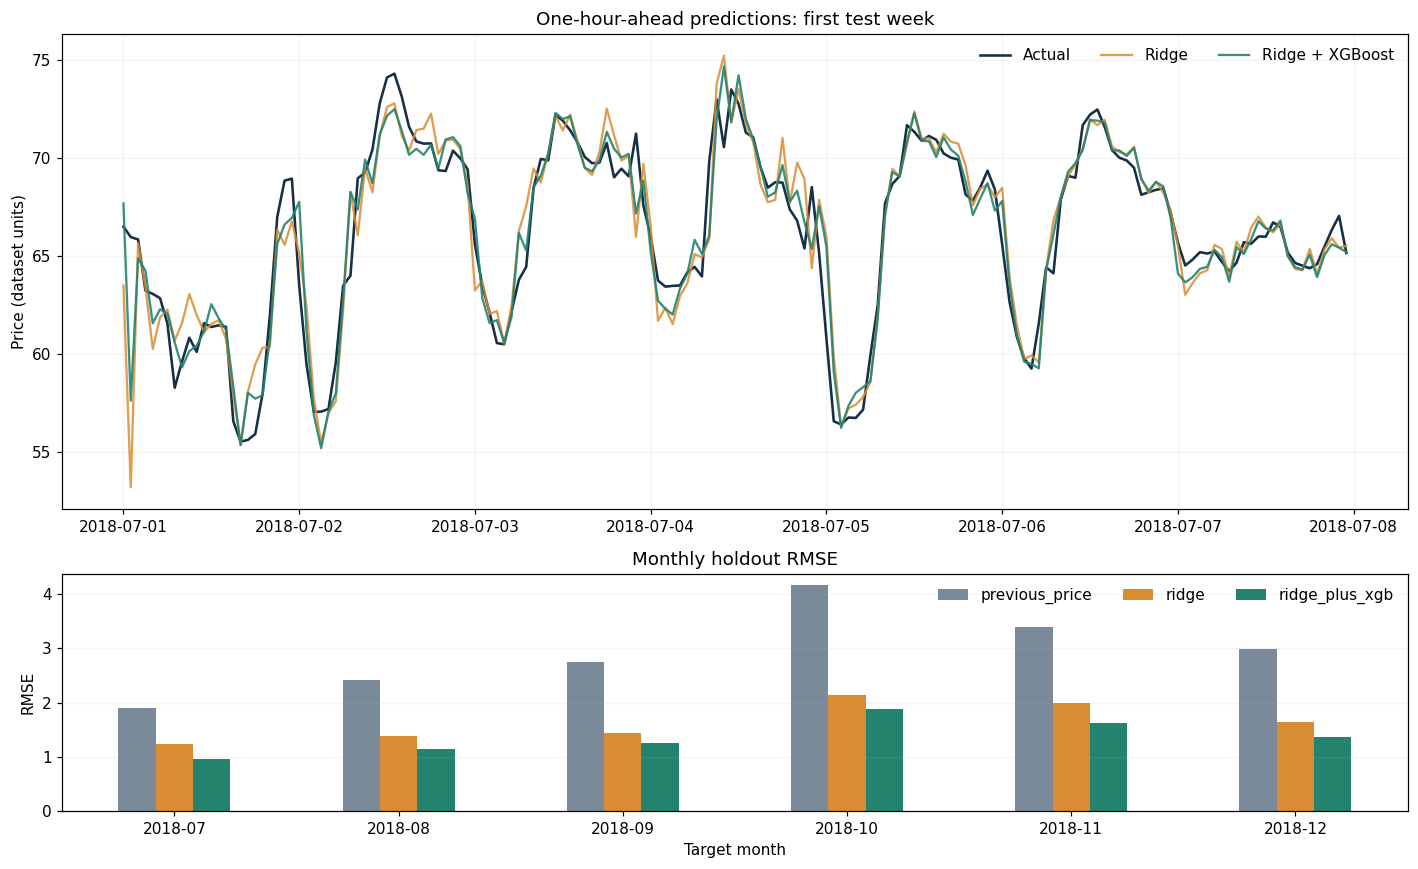

In [25]:
monthly_rows=[]
for month, group in test_predictions.groupby(test_predictions.index.strftime('%Y-%m')):
    for model in ['previous_price','ridge','ridge_plus_xgb']:
        monthly_rows.append({'month':month,'model':model,'rows':len(group),
                             **metric_dict(group.actual,group[model])})
monthly_metrics=pd.DataFrame(monthly_rows)
display(monthly_metrics.pivot(index='month',columns='model',values='RMSE').round(3))

fig,axes=plt.subplots(2,1,figsize=(13,8),gridspec_kw={'height_ratios':[2,1]})
week=test_predictions.iloc[:168]
axes[0].plot(week.index,week.actual,label='Actual',color='#182f48',linewidth=1.7)
axes[0].plot(week.index,week.ridge,label='Ridge',color='#da8c32',alpha=.85)
axes[0].plot(week.index,week.ridge_plus_xgb,label='Ridge + XGBoost',color='#24836f',alpha=.9)
axes[0].set(title='One-hour-ahead predictions: first test week',ylabel='Price (dataset units)')
axes[0].legend(ncol=3,frameon=False)
axes[0].grid(alpha=.15)
monthly_metrics.pivot(index='month',columns='model',values='RMSE').plot.bar(
    ax=axes[1],color=['#7b8a9b','#da8c32','#24836f'],rot=0)
axes[1].set(title='Monthly holdout RMSE',ylabel='RMSE',xlabel='Target month')
axes[1].legend(frameon=False,ncol=3)
axes[1].grid(axis='y',alpha=.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'forecast_evaluation.png',dpi=150,bbox_inches='tight')
plt.show()


### Save predictions and a reusable fitted model

The saved bundle contains the evaluation models trained through June 2018,
their feature order, availability assumption and selected settings. The CSV
contains every held-out hourly prediction with its true observed price.
`predict_next_hour` below requires target-hour published forecast inputs;
no price beyond the CSV is fabricated.


In [26]:
versions={'python':platform.python_version(),'numpy':np.__version__,
          'pandas':pd.__version__,'scikit-learn':sklearn.__version__,
          'xgboost':xgboost.__version__}
model_bundle={
    'ridge':ridge_model,'residual_tree':residual_tree,
    'features':selected_features,'ridge_config':ridge_config,
    'tree_config':hybrid_config,'correction_weight':correction_weight,
    'actual_delay_hours':ACTUAL_DELAY_HOURS,'trained_before':str(TEST_START),
    'tree_rounds':final_rounds,'versions':versions,
}
test_predictions.to_csv(OUTPUT_DIR/'test_predictions.csv',index_label='time')
test_metrics.to_csv(OUTPUT_DIR/'test_metrics.csv')
monthly_metrics.to_csv(OUTPUT_DIR/'monthly_test_metrics.csv',index=False)
feature_manifest.to_csv(OUTPUT_DIR/'feature_availability.csv',index=False)
ridge_ranking.to_csv(OUTPUT_DIR/'ridge_validation_ranking.csv',index=False)
ridge_cv_folds.to_csv(OUTPUT_DIR/'ridge_validation_folds.csv',index=False)
hybrid_ranking.to_csv(OUTPUT_DIR/'hybrid_validation_ranking.csv',index=False)
joblib.dump(model_bundle,OUTPUT_DIR/'price_forecast_model.joblib')
summary={
    'task':'one hour ahead, updated hourly',
    'selected_model':selected_model_name,
    'ridge_config':ridge_config,'hybrid_config':hybrid_config,
    'correction_weight':correction_weight,'final_rounds':final_rounds,
    'test_start':str(TEST_START),'test_rows':len(test_predictions),
    'test_metrics':test_metrics.to_dict(orient='index'),
    'data_sha256':hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'versions':versions,
    'availability_assumption':f'actuals available with {ACTUAL_DELAY_HOURS}-hour lag; target-hour forecasts already published',
}
(OUTPUT_DIR/'forecast_summary.json').write_text(json.dumps(summary,indent=2))
print('Saved predictions, metrics, feature audit, fitted model and chart to:',OUTPUT_DIR)


Saved predictions, metrics, feature audit, fitted model and chart to: /Users/jiongwu/Documents/Codex/2026-11-09/fo/outputs


In [27]:
def predict_next_hour(history, known_next_hour, bundle=model_bundle):
    """Predict one hour after history ends using supplied published forecasts.

    history: raw-column DataFrame indexed by tz-aware hourly target timestamps.
    known_next_hour: one-row DataFrame with the four forecast columns below.
    The target actual price must not be provided or used.
    """
    history=history.sort_index()
    if history.index.tz is None or not history.index.is_unique:
        raise ValueError('history needs a unique timezone-aware hourly index')
    history=history.tz_convert(TIMEZONE)
    if not history.index.equals(pd.date_range(history.index.min(),history.index.max(),freq='h')):
        raise ValueError('history must retain the complete hourly grid')
    if len(history)<168+bundle['actual_delay_hours']:
        raise ValueError('Provide at least 168 + actual_delay_hours of history')
    next_time=history.index[-1]+pd.Timedelta(hours=1)
    if len(known_next_hour)!=1 or known_next_hour.index[0]!=next_time:
        raise ValueError('known_next_hour must contain exactly the next target hour')
    required=['price day ahead','total load forecast',
              'forecast solar day ahead','forecast wind onshore day ahead']
    if any(c not in known_next_hour for c in required):
        raise ValueError('Provide all four published target-hour forecast columns: '+str(required))
    if known_next_hour[required].isna().any().any():
        raise ValueError('Published next-hour forecasts cannot be missing')
    next_row=pd.DataFrame(np.nan,index=pd.DatetimeIndex([next_time]),columns=history.columns)
    next_row.loc[next_time,required]=known_next_hour.iloc[0][required].to_numpy()
    extended=pd.concat([history,next_row])
    features,_,anchor,_,_=make_features(extended,bundle['actual_delay_hours'])
    row=features.loc[[next_time],bundle['features']]
    if row.filter(regex='^price_lag').isna().any().any():
        raise ValueError('Required historical actual prices are missing')
    base=float(anchor.loc[next_time]) if bundle['ridge_config']['target']=='baseline_residual' else 0.
    if not np.isfinite(base):
        raise ValueError('Historical price/day-ahead information required for the baseline is missing')
    ridge_price=float(bundle['ridge'].predict(row)[0])+base
    correction=float(bundle['residual_tree'].predict(row)[0])
    return pd.Series({'ridge':ridge_price,
                      'ridge_plus_xgb':ridge_price+bundle['correction_weight']*correction},
                     name=next_time)

# Verify the inference helper against one untouched hourly holdout prediction.
replay_time=test_predictions.index[0]
forecast_columns=['price day ahead','total load forecast',
                  'forecast solar day ahead','forecast wind onshore day ahead']
replay=predict_next_hour(df.loc[df.index<replay_time],df.loc[[replay_time],forecast_columns])
np.testing.assert_allclose(replay.to_numpy(),
    test_predictions.loc[replay_time,['ridge','ridge_plus_xgb']].to_numpy(),rtol=1e-6)
print('Inference replay matches the recorded first holdout prediction.')
display(replay)
# For a future hour: obtain its published four-column forecast row, then call
# predict_next_hour(updated_raw_history, published_next_hour_row).


Inference replay matches the recorded first holdout prediction.


ridge             63.496467
ridge_plus_xgb    67.689265
Name: 2018-07-01 00:00:00+02:00, dtype: float64

### Interpretation and next experiments

- Judge model skill against both simple baselines, and inspect monthly errors.
- The chosen model is based on validation RMSE; test results are a historical
  assessment, not a reason to retune on the same holdout.
- A model can have a lower RMSE but a higher MAE: RMSE puts more weight on spikes.
- No target-normality transform is required. Scaling and imputation are fitted
  only on training rows. No same-hour actual physical measurements are used.
- The model bundle is intentionally the pre-test fit. For deployment with newer
  data, refit the already-selected configuration on available history before
  producing future forecasts, and verify actual publication delays.

References: [scikit-learn Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html),
[time-series validation](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html),
[XGBoost early stopping](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html).
